<a href="https://colab.research.google.com/github/XuningZhuang/MSSP6070/blob/main/WeeklyModules/Week10/Week_10_ImprovedWeek8Exercise_Xuning_Zhuan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 10 — Improving Coding with Generative AI

**Original notebook:** Week_8_Exercise_Xuning_Zhuang.ipynb  


**Changes suggested by AI:**
1. Add basic data-quality checks with `shape` and `isnull().sum()`.
2. Use `low_memory=False` while reading the CSV to reduce mixed-type inference warnings.
3. Calculate the linear regression `slope` and `intercept` once and reuse them for the forecast and trend line.
4. Print a clear product summary and use a variable for the top product.
5. Separate calculations and figures into distinct cells, and document the partial-year limitation.


## Cell 1 — Load CSV
Read `InternetSales.csv` from GitHub and clone the data. The CSV is the same input dataset used in Week 8.

In [20]:
from google.colab import userdata

github_token = userdata.get('6070777')
owner = 'XuningZhuang'
repository = 'MSSP6070'

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

# Clone the repository
!git clone {clone_url}

fatal: destination path 'MSSP6070' already exists and is not an empty directory.


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('/content/MSSP6070/data/InternetSales.csv', encoding='latin-1', low_memory=False)

## Cell 2 — Check data
`shape` shows rows and columns; `isnull().sum()` counts missing values in the two variables used for the time-series analysis.

In [22]:
print('Rows and columns:', df.shape)
print('Missing values:')
print(df[['OrderDate', 'SalesAmount']].isnull().sum())
print('Missing product names:', df['EnglishProductName'].isnull().sum())

Rows and columns: (60398, 60)
Missing values:
OrderDate      0
SalesAmount    0
dtype: int64
Missing product names: 0


## Cell 3 — Prepare dates and calculate annual sales
This is the same `to_datetime()`, `groupby()`, and `sum()` logic as the original notebook.

In [23]:
df['OrderDate'] = pd.to_datetime(df['OrderDate'])

yearly_sales = df.groupby(df['OrderDate'].dt.year)['SalesAmount'].sum()

print(yearly_sales)

OrderDate
2010    4.342104e+04
2011    7.075526e+06
2012    5.842485e+06
2013    1.635155e+07
2014    4.569472e+04
Name: SalesAmount, dtype: float64


## Cell 4 — Calculate the five-year forecast AND historical trend line
`np.polyfit(..., 1)` fits one straight line. The coefficients are used twice, rather than running `polyfit` twice.

In [24]:
years = np.array(yearly_sales.index)
sales = yearly_sales.values

slope, intercept = np.polyfit(years, sales, 1)

forecast_years = np.arange(years.max() + 1, years.max() + 6)
forecast_sales = intercept + slope * forecast_years
forecast = pd.Series(forecast_sales, index=forecast_years)

trend_line = intercept + slope * years

print('Five-year forecast:')
print(forecast)

Five-year forecast:
2015    8.655907e+06
2016    9.583964e+06
2017    1.051202e+07
2018    1.144008e+07
2019    1.236814e+07
dtype: float64


## Cell 5 — Show historical sales and forecast
Bars show observed sales; the line with circle markers shows forecast sales.

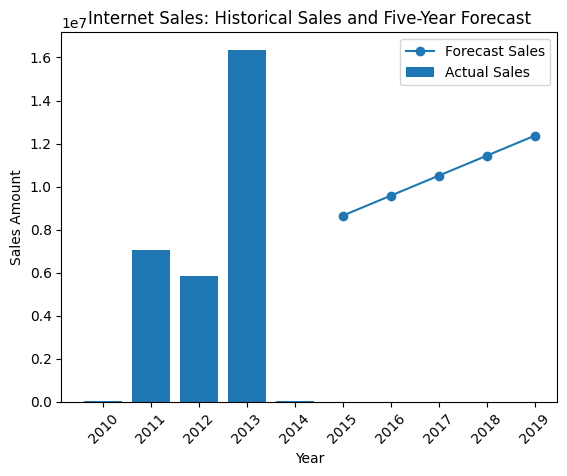

In [25]:
plt.figure()
plt.bar(years, sales, label='Actual Sales')
plt.plot(forecast_years, forecast_sales, marker='o', label='Forecast Sales')
plt.xlabel('Year')
plt.ylabel('Sales Amount')
plt.title('Internet Sales: Historical Sales and Five-Year Forecast')
plt.legend()
plt.xticks(list(years) + list(forecast_years), rotation=45)
plt.show()

## Cell 6 — Find the highest-selling individual product
Use `sum` to rank products by total sales, not by the number of transactions.

In [26]:
product_stats = df.groupby('EnglishProductName')['SalesAmount'].agg(
    ['count', 'sum', 'mean', 'median', 'std']
).sort_values('sum', ascending=False)

print(product_stats.head())

top_product = product_stats.index[0]
print('Top-selling product:', top_product)
print(product_stats.loc[top_product])

                         count           sum         mean   median         std
EnglishProductName                                                            
Mountain-200 Black, 46     620  1.373470e+06  2215.273465  2294.99  115.188180
Mountain-200 Black, 42     614  1.363142e+06  2220.101129  2294.99  113.256820
Mountain-200 Silver, 38    596  1.339463e+06  2247.420789  2319.99  113.109387
Mountain-200 Silver, 46    580  1.301100e+06  2243.276032  2319.99  114.919793
Mountain-200 Black, 38     582  1.294866e+06  2224.855913  2294.99  111.120758
Top-selling product: Mountain-200 Black, 46
count     6.200000e+02
sum       1.373470e+06
mean      2.215273e+03
median    2.294990e+03
std       1.151882e+02
Name: Mountain-200 Black, 46, dtype: float64


## Cell 7 — Plot the historical trend line
The same `trend_line` computed in Cell 4 is reused here.

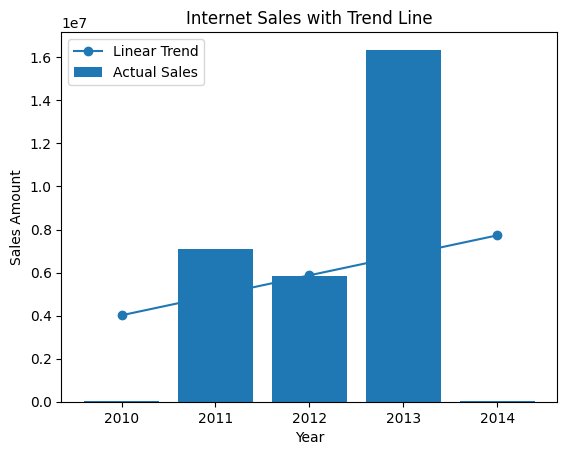

In [27]:
plt.figure()
plt.bar(years, sales, label='Actual Sales')
plt.plot(years, trend_line, marker='o', label='Linear Trend')
plt.xlabel('Year')
plt.ylabel('Sales Amount')
plt.title('Internet Sales with Trend Line')
plt.legend()
plt.xticks(years, rotation=0)
plt.show()